In [14]:
from google.colab import files
uploaded=files.upload()

Saving online_retail_II.xlsx to online_retail_II (2).xlsx


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

sheets = pd.read_excel(file_name, sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)

print("Dataset Shape:", df.shape)
print(df.head())
print(df.columns.tolist())


In [ ]:

df.columns = df.columns.str.strip()

df = df.dropna(subset=["Customer ID", "Invoice", "InvoiceDate"])

df["Invoice"] = df["Invoice"].astype(str).str.strip()
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

df = df.dropna(
    subset=["InvoiceDate", "Quantity", "Price"]
)

df = df[
    (~df["Invoice"].str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

df["Revenue"] = df["Quantity"] * df["Price"]

print("Cleaned dataset shape:", df.shape)
print(df.head())


Cleaned dataset shape: (805549, 9)
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  Revenue  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom     83.4  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom    100.8  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom     30.0  


In [ ]:

# Count unique invoices for each customer
customer_orders = (
    df.groupby("Customer ID")["Invoice"]
    .nunique()
    .reset_index()
)

customer_orders.columns = ["Customer ID", "Total Orders"]

# Identify first-time and repeat customers
customer_orders["Customer Segment"] = np.where(
    customer_orders["Total Orders"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

# Display customer segments
print(customer_orders.head(10))

print("\nCustomer Segment Summary:")
print(customer_orders["Customer Segment"].value_counts())


   Customer ID  Total Orders   Customer Segment
0      12346.0            12    Repeat Customer
1      12347.0             8    Repeat Customer
2      12348.0             5    Repeat Customer
3      12349.0             4    Repeat Customer
4      12350.0             1  One-Time Customer
5      12351.0             1  One-Time Customer
6      12352.0            10    Repeat Customer
7      12353.0             2    Repeat Customer
8      12354.0             1  One-Time Customer
9      12355.0             2    Repeat Customer

Customer Segment Summary:
Customer Segment
Repeat Customer      4255
One-Time Customer    1623
Name: count, dtype: int64


In [ ]:

total_customers = customer_orders["Customer ID"].nunique()

repeat_customers = (
    customer_orders["Total Orders"] > 1
).sum()

one_time_customers = (
    customer_orders["Total Orders"] == 1
).sum()

repeat_rate = (
    repeat_customers / total_customers * 100
    if total_customers > 0 else 0
)

print("Total Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print("One-Time Customers:", one_time_customers)
print(f"Repeat Purchase Rate: {repeat_rate:.2f}%")


Total Customers: 5878
Repeat Customers: 4255
One-Time Customers: 1623
Repeat Purchase Rate: 72.39%


In [ ]:

# Calculate order value for each invoice
order_values = (
    df.groupby(["Customer ID", "Invoice"])["Revenue"]
    .sum()
    .reset_index()
)

order_values.columns = [
    "Customer ID", "Invoice", "Order Value"
]

# Add customer segment
order_values = order_values.merge(
    customer_orders[
        ["Customer ID", "Customer Segment"]
    ],
    on="Customer ID",
    how="left"
)

# Compare Average Order Value
aov_comparison = (
    order_values.groupby("Customer Segment")["Order Value"]
    .mean()
    .reset_index()
)

aov_comparison.columns = [
    "Customer Segment", "Average Order Value"
]

print(aov_comparison.round(2))


    Customer Segment  Average Order Value
0  One-Time Customer               350.08
1    Repeat Customer               485.92


In [ ]:

segment_summary = (
    customer_orders.groupby("Customer Segment")
    .agg(
        Total_Customers=("Customer ID", "nunique"),
        Average_Orders=("Total Orders", "mean")
    )
    .reset_index()
)

segment_summary["Customer Percentage"] = (
    segment_summary["Total_Customers"]
    / segment_summary["Total_Customers"].sum() * 100
)

segment_summary = segment_summary.round(2)

print(segment_summary)


    Customer Segment  Total_Customers  Average_Orders  Customer Percentage
0  One-Time Customer             1623            1.00                27.61
1    Repeat Customer             4255            8.31                72.39


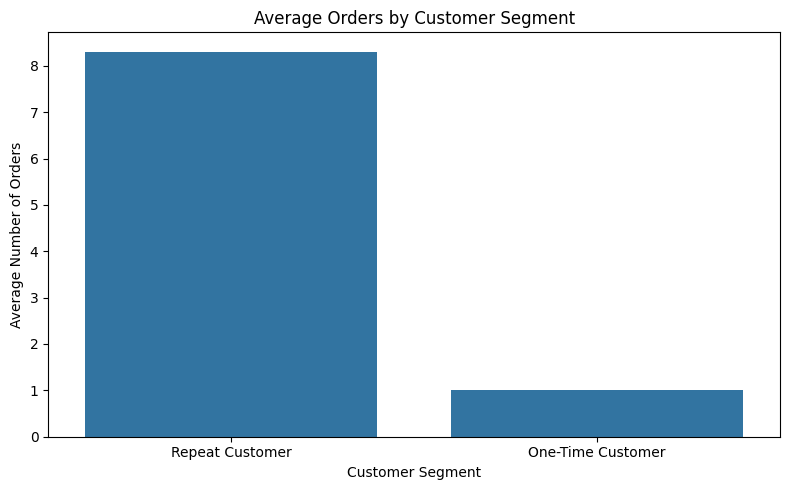

In [ ]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=customer_orders,
    x="Customer Segment",
    y="Total Orders",
    estimator="mean",
    errorbar=None
)

plt.title("Average Orders by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Number of Orders")
plt.tight_layout()
plt.show()


In [ ]:

# Calculate key business metrics

total_orders = df["Invoice"].nunique()
total_revenue = df["Revenue"].sum()

repeat_aov = aov_comparison.loc[
    aov_comparison["Customer Segment"] == "Repeat Customer",
    "Average Order Value"
].iloc[0]

one_time_aov = aov_comparison.loc[
    aov_comparison["Customer Segment"] == "One-Time Customer",
    "Average Order Value"
].iloc[0]

print("========== BUSINESS INSIGHTS ==========")
print(f"Total Customers: {total_customers:,}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Repeat Customers: {repeat_customers:,}")
print(f"Repeat Purchase Rate: {repeat_rate:.2f}%")
print(f"One-Time Customer AOV: {one_time_aov:,.2f}")
print(f"Repeat Customer AOV: {repeat_aov:,.2f}")

if repeat_aov > one_time_aov:
    print("Insight: Repeat customers have a higher average order value.")
elif repeat_aov < one_time_aov:
    print("Insight: One-time customers have a higher average order value.")
else:
    print("Insight: Both segments have the same average order value.")


========== BUSINESS INSIGHTS ==========
Total Customers: 5,878
Total Orders: 36,969
Total Revenue: 17,743,429.18
Repeat Customers: 4,255
Repeat Purchase Rate: 72.39%
One-Time Customer AOV: 350.08
Repeat Customer AOV: 485.92
Insight: Repeat customers have a higher average order value.


In [ ]:

# Export analysis results
customer_orders.to_csv(
    "Customer_Segment_Table.csv", index=False
)

segment_summary.to_csv(
    "Customer_Segment_Summary.csv", index=False
)

aov_comparison.to_csv(
    "AOV_Comparison.csv", index=False
)

# Export overall KPI summary
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Repeat Customers",
        "One-Time Customers",
        "Repeat Purchase Rate (%)",
        "Total Orders",
        "Total Revenue"
    ],
    "Value": [
        total_customers,
        repeat_customers,
        one_time_customers,
        round(repeat_rate, 2),
        total_orders,
        round(total_revenue, 2)
    ]
})

kpi_summary.to_csv("Repeat_Purchase_KPI_Summary.csv", index=False)

print("All CSV files saved successfully!")


All CSV files saved successfully!


In [ ]:

from google.colab import files

for filename in [
    "Customer_Segment_Table.csv",
    "Customer_Segment_Summary.csv",
    "AOV_Comparison.csv",
    "Repeat_Purchase_KPI_Summary.csv"
]:
    files.download(filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

df.to_csv("Cleaned_Online_Retail.csv", index=False)

from google.colab import files
files.download("Cleaned_Online_Retail.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>